# TIGER-pair V17: reproducible results

This notebook replays all 420 archived predictions, verifies four family-macro metrics and the 164 jointly corrected ablation tests, and plots the complete landscape. No GPU or model weights are needed for these cells. Model training and checkpoint inference are documented in the root README.

The reference is P11, unsigned quota 20,000, neighbour validation. Results are exploratory because main-model selection used this external panel.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
assert (ROOT / "configs/ablation_groups.json").is_file()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
from reproduce_v17 import run
validation = run(ROOT / "outputs/notebook_replay")
validation

{
  "status": "PASS",
  "configurations": 42,
  "seed_predictions": 420,
  "family_scores": 4620,
  "paired_tests": 164,
  "numeric_checks": 21652,
  "holm_significant_tests": 0
}


{'status': 'PASS',
 'configurations': 42,
 'seed_predictions': 420,
 'family_scores': 4620,
 'paired_tests': 164,
 'numeric_checks': 21652,
 'holm_significant_tests': 0}

## Ten-seed main-model results

Metrics are computed in each family, then averaged equally over 11 families. Each seed uses the calibrated mean of its five fold predictions. The SD is the sample SD across seeds 120–129, not variation across biological samples.

In [2]:
import pandas as pd
summary = pd.read_csv(ROOT / "outputs/notebook_replay/tiger_summary.csv")
summary.loc[summary.arm == "factor_P11", ["metric", "mean", "sd", "ci_low", "ci_high"]]

,metric,mean,sd,ci_low,ci_high
64,PCC,0.654320,0.016803,0.642300,0.666340
65,KCC,0.472940,0.021018,0.457904,0.487976
66,log10MAE,0.381269,0.007719,0.375747,0.386791
67,RSE,0.665917,0.025618,0.647591,0.684244


## Complete ablation landscape

Points show the mean and horizontal intervals show ±1 sample SD. Dashed lines mark the reference. Colours distinguish experiment groups. All 41 controls × four metrics are jointly corrected; no Holm-adjusted P < 0.05. These intervals reflect training-seed variability on the same panel.

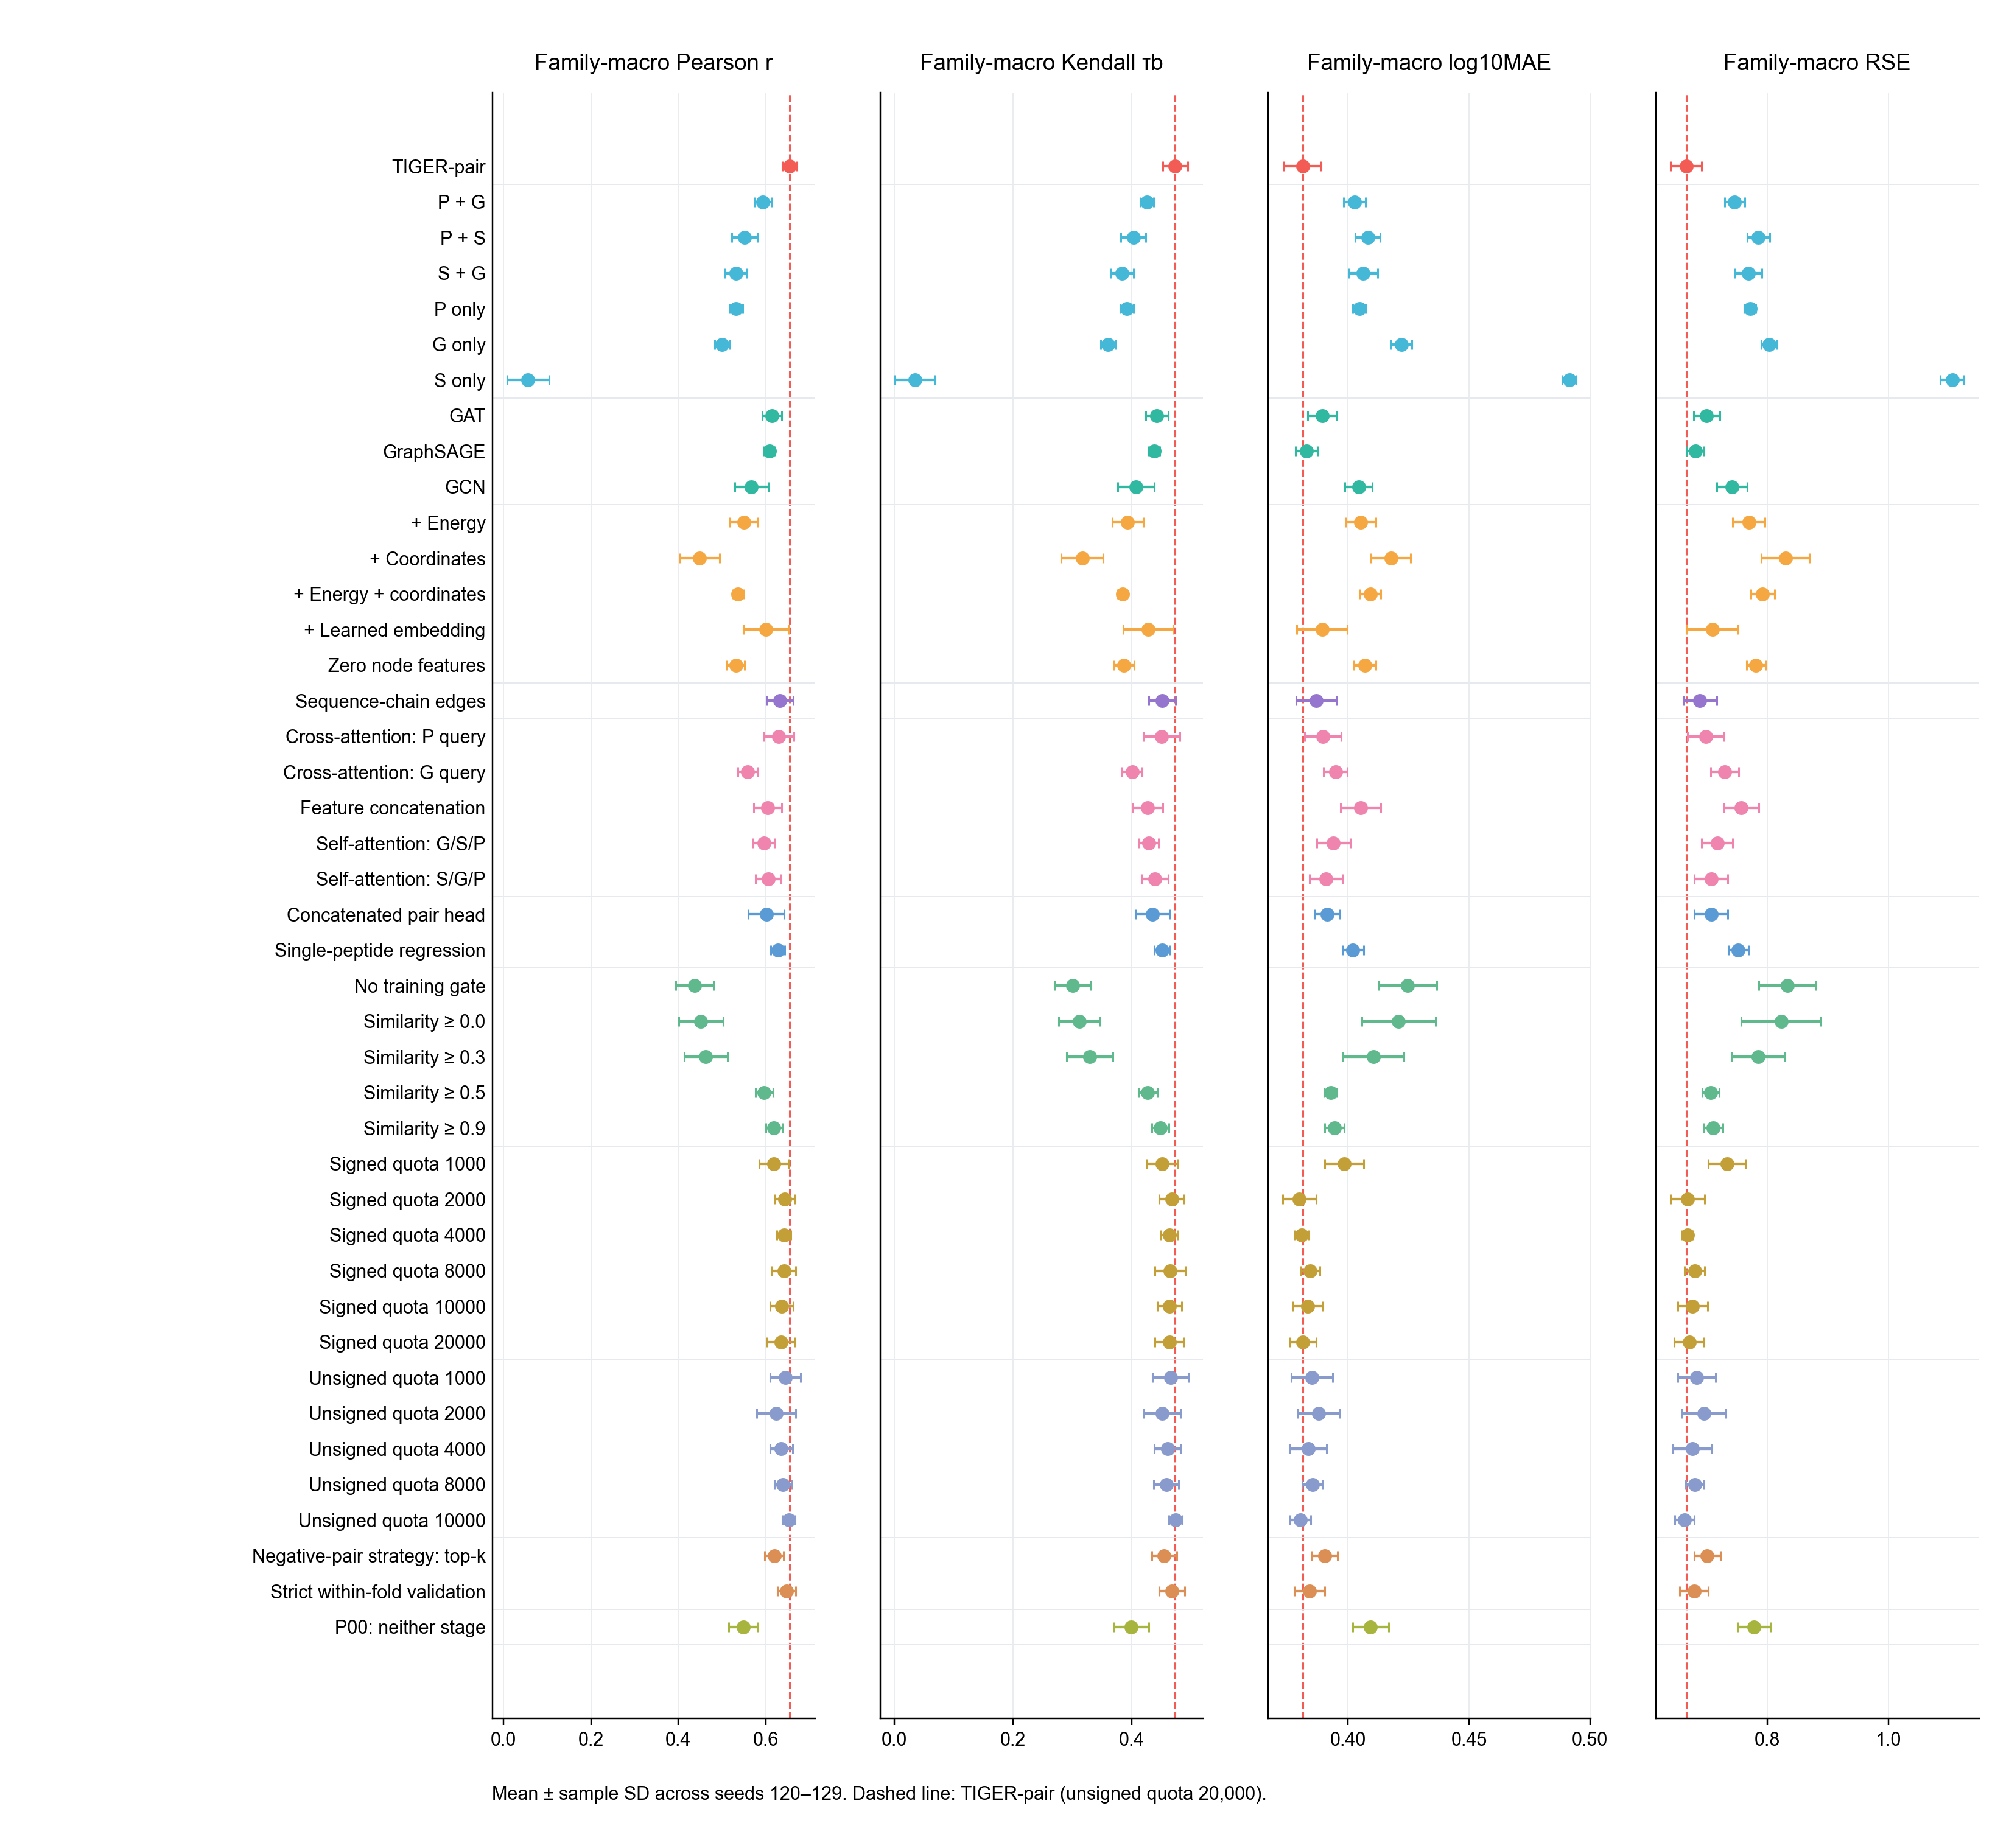

In [3]:
from plot_v17 import plot
from IPython.display import Image, display
figure = plot(ROOT / "outputs/notebook_figures")
display(Image(filename=str(figure)))

## Pairwise tests

P values are two-sided paired-seed Wilcoxon tests. Signed/unsigned sampling changes both bin sign handling and resolution. The single-head result is a reused complete ten-seed batch. P00 removes the entire classification-pretraining stage and regression negatives.

In [4]:
tests = pd.read_csv(ROOT / "outputs/notebook_replay/ablation_contrasts.csv")
print("Tests:", len(tests), "Minimum Holm P:", tests.p_holm.min())
tests.sort_values(["metric", "delta_a_minus_b"]).head(12)

Tests: 164 Minimum Holm P: 0.3203125


,arm,metric,delta_a_minus_b,ci_low,ci_high,p_raw,p_holm
149,s4_mod_s,KCC,-0.438361,-0.470850,-0.405873,0.001953,0.320312
129,s4_gate_off,KCC,-0.172496,-0.194355,-0.150637,0.001953,0.320312
41,S4_sim00,KCC,-0.161633,-0.187183,-0.136082,0.001953,0.320312
57,S4_sp,KCC,-0.156529,-0.182851,-0.130207,0.001953,0.320312
45,S4_sim03,KCC,-0.143509,-0.165044,-0.121973,0.001953,0.320312
133,s4_mod_g,KCC,-0.113049,-0.132935,-0.093163,0.001953,0.320312
153,s4_mod_sg,KCC,-0.089186,-0.108874,-0.069498,0.001953,0.320312
37,S4_sep,KCC,-0.088852,-0.105843,-0.071861,0.001953,0.320312
25,S4_nodezero,KCC,-0.086027,-0.104570,-0.067485,0.001953,0.320312
137,s4_mod_p,KCC,-0.081177,-0.096916,-0.065438,0.001953,0.320312
